# Store Sales — Step 3: Baseline (Random Walk)

**Author:** Bella Ren

The simplest possible forecast: a **random walk**, i.e. ARIMA(0,1,0) without drift.
The forecast for every future day equals the last observed value:

$$\hat y_{T+h} = y_T, \quad h = 1, \dots, 16$$

Zero series (no sales in the last 30 days) are forecast as 0.
Every later model must beat this score on the validation split.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (14, 4)
plt.rcParams['axes.grid'] = True

# Works both locally (data/) and inside the repo (kaggle_comp/notebooks -> ../data/)
DATA = 'data/' if os.path.exists('data/processed.parquet') else '../data/'
VALID_START = pd.Timestamp('2017-07-31')
TEST_START = pd.Timestamp('2017-08-16')
K = ['store_nbr', 'family']

df = pd.read_parquet(DATA + 'processed.parquet',
                     columns=['id', 'date', 'store_nbr', 'family', 'sales', 'split', 'zero_series'])
print(df.shape)

(3036528, 7)


In [2]:
def rmsle(y_true, y_pred):
    return np.sqrt(np.mean((np.log1p(y_pred) - np.log1p(y_true)) ** 2))


def random_walk(history, horizon, zero_window=30):
    """Forecast = last observed value of each series; series with zero sales
    in the last `zero_window` days of history are forecast as 0."""
    last_date = history.date.max()
    last = history[history.date == last_date].set_index(K).sales.rename('pred')
    recent = history[history.date > last_date - pd.Timedelta(days=zero_window)]
    is_zero = recent.groupby(K, observed=True).sales.sum() == 0
    last[is_zero.reindex(last.index, fill_value=False)] = 0
    return horizon.merge(last.reset_index(), on=K, how='left')

## 1. Validation
History = everything up to 2017-07-30; forecast 2017-07-31 → 2017-08-15 (16 days).

In [3]:
hist = df[df.split == 'train']
val = random_walk(hist, df[df.split == 'valid'].copy())
assert val.pred.notna().all()

score_rw = rmsle(val.sales, val.pred)
print('Last observed date used:', hist.date.max().date(), '(%s)' % hist.date.max().day_name())
print('Validation RMSLE, random walk: %.4f' % score_rw)

Last observed date used: 2017-07-30 (Sunday)
Validation RMSLE, random walk: 0.6595


## 2. Error by forecast horizon
The random-walk forecast is flat, so its error depends on how typical the last observed day was
and on the weekly cycle of the target days.

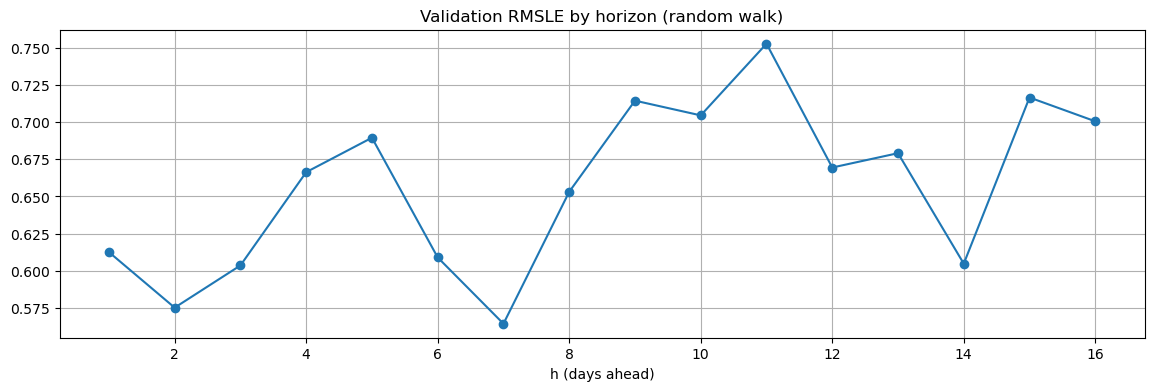

In [4]:
val['h'] = (val.date - VALID_START).dt.days + 1
by_h = val.groupby('h').apply(lambda g: rmsle(g.sales, g.pred), include_groups=False)
ax = by_h.plot(marker='o', title='Validation RMSLE by horizon (random walk)')
ax.set_xlabel('h (days ahead)'); plt.show()

## 3. Example series: actual vs random-walk forecast

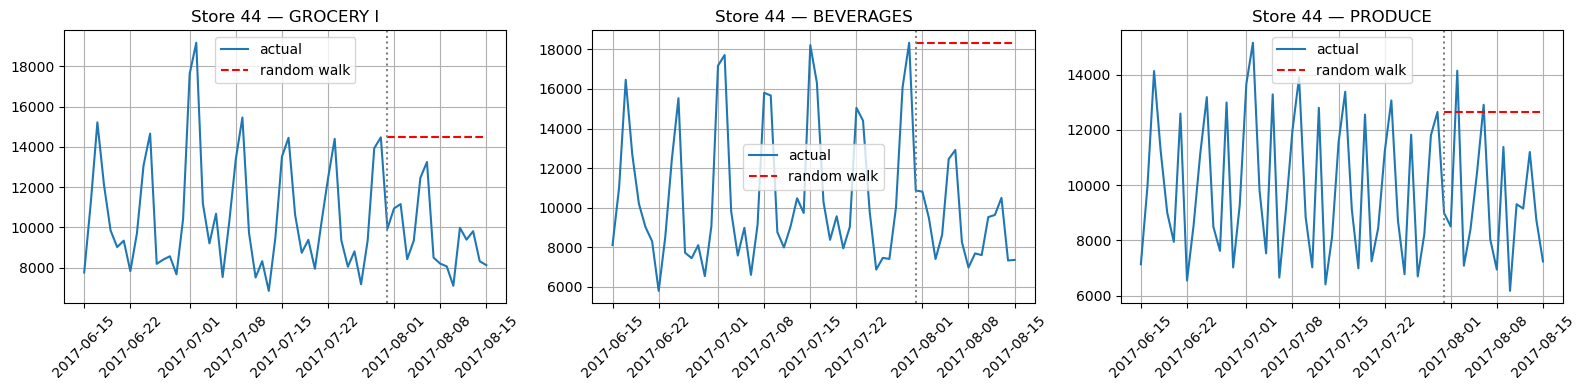

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, fam in zip(axes, ['GROCERY I', 'BEVERAGES', 'PRODUCE']):
    s = df[(df.store_nbr == 44) & (df.family == fam) & (df.date >= '2017-06-15') & (df.split != 'test')]
    ax.plot(s.date, s.sales, label='actual')
    v = val[(val.store_nbr == 44) & (val.family == fam)]
    ax.plot(v.date, v.pred, 'r--', label='random walk')
    ax.axvline(VALID_START, color='gray', ls=':')
    ax.set_title(f'Store 44 — {fam}'); ax.tick_params(axis='x', rotation=45); ax.legend()
plt.tight_layout(); plt.show()

## 4. Test forecast and submission file
Refit on train + valid: forecast 2017-08-16 → 2017-08-31 from the last value on 2017-08-15.

In [6]:
test_pred = random_walk(df[df.split != 'test'], df[df.split == 'test'].copy())
sub = test_pred[['id', 'pred']].rename(columns={'pred': 'sales'})
sub['id'] = sub.id.astype(int)
sub = sub.sort_values('id')
assert len(sub) == 28512 and sub.sales.notna().all() and (sub.sales >= 0).all()
os.makedirs('submissions', exist_ok=True)
sub.to_csv('submissions/submission_random_walk.csv', index=False)
print('Saved submissions/submission_random_walk.csv', sub.shape)
sub.head()

Saved submissions/submission_random_walk.csv (28512, 2)


,id,sales
0,3000888,4.0
16,3000889,0.0
32,3000890,4.0
48,3000891,1942.0
64,3000892,0.0
